# 01 — Data Cleaning

**Goal:** prepare `data.csv` (training, has `W`) and `predict.csv` (scoring, no `W`) for a model that predicts team wins.

Steps:
1. Load & inspect
2. Missing values & duplicates
3. Schema alignment between train and predict
4. Target leakage & redundant columns
5. Data types
6. Encoded-column sanity checks
7. Internal consistency checks (baseball logic)
8. Outliers
9. Save cleaned files

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid')

# raw and cleaned CSVs live in Model-3-Project/Data; works whether the kernel starts in notebooks/, Model-3-Project/ or DSAI/
DATA_DIR = next(p for p in [Path('../Data'), Path('Data'), Path('Model-3-Project/Data')] if (p / 'data.csv').exists())
RAW_DIR = OUT_DIR = DATA_DIR
OUT_DIR.mkdir(exist_ok=True)

train_raw = pd.read_csv(RAW_DIR / 'data.csv')
pred_raw = pd.read_csv(RAW_DIR / 'predict.csv')
train, pred = train_raw.copy(), pred_raw.copy()
print('train:', train.shape, '| predict:', pred.shape)

train: (1412, 51) | predict: (400, 47)


## 1. Load & inspect

In [2]:
train.head()

,yearID,teamID,G,R,AB,H,2B,3B,HR,BB,SO,SB,RA,ER,ERA,CG,SHO,SV,IPouts,HA,HRA,BBA,SOA,E,DP,FP,mlb_rpg,era_1,era_2,era_3,era_4,era_5,era_6,era_7,era_8,decade_1910,decade_1920,decade_1930,decade_1940,decade_1950,decade_1960,decade_1970,decade_1980,decade_1990,decade_2000,decade_2010,W,ID,year_label,decade_label,win_bins
0,1935,BOS,154,718,5288,1458,281,63,69,609,470.0,91,732,619,4.05,82,6,11,4128,1520,67,520,470,190,136.0,0.969,4.864690,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,78,317,1935,1930s,3
1,1993,TEX,162,835,5510,1472,284,39,181,483,984.0,113,751,684,4.28,20,6,45,4314,1476,144,562,957,130,145.0,0.979,4.597620,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,86,2162,1993,1990s,3
2,2016,SEA,162,768,5583,1446,251,17,223,506,1288.0,56,707,647,4.00,2,8,49,4371,1410,213,460,1318,89,158.0,0.985,4.477759,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,86,1895,2016,2010s,3
3,1938,CHN,154,713,5333,1435,242,70,65,522,476.0,49,598,523,3.37,67,16,18,4188,1414,71,454,583,135,151.0,0.978,4.902046,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,89,428,1938,1930s,3
4,1996,BOS,162,928,5756,1631,308,31,209,642,1020.0,91,921,810,5.00,17,5,37,4374,1606,185,722,1165,135,152.0,0.978,5.035509,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,85,375,1996,1990s,3


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1412 entries, 0 to 1411
Data columns (total 51 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   yearID        1412 non-null   int64  
 1   teamID        1412 non-null   str    
 2   G             1412 non-null   int64  
 3   R             1412 non-null   int64  
 4   AB            1412 non-null   int64  
 5   H             1412 non-null   int64  
 6   2B            1412 non-null   int64  
 7   3B            1412 non-null   int64  
 8   HR            1412 non-null   int64  
 9   BB            1412 non-null   int64  
 10  SO            1412 non-null   float64
 11  SB            1412 non-null   int64  
 12  RA            1412 non-null   int64  
 13  ER            1412 non-null   int64  
 14  ERA           1412 non-null   float64
 15  CG            1412 non-null   int64  
 16  SHO           1412 non-null   int64  
 17  SV            1412 non-null   int64  
 18  IPouts        1412 non-null   int64  
 

In [4]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
yearID,1412.0,1968.611190,32.289657,1904.00000,1942.000000,1973.000000,1998.000000,2016.000000
G,1412.0,159.066572,3.727970,150.00000,155.000000,162.000000,162.000000,164.000000
R,1412.0,699.837110,102.675093,371.00000,633.000000,700.000000,762.000000,1067.000000
AB,1412.0,5417.891643,167.599913,4822.00000,5305.750000,5457.500000,5536.000000,5769.000000
H,1412.0,1415.412181,105.095226,1044.00000,1349.000000,1414.000000,1486.000000,1783.000000
2B,1412.0,245.478045,45.553750,110.00000,213.000000,246.000000,280.000000,376.000000
3B,1412.0,44.012040,19.578746,6.00000,30.000000,39.000000,54.000000,122.000000
HR,1412.0,119.468130,55.586287,4.00000,82.000000,124.000000,159.000000,264.000000
BB,1412.0,514.356232,83.774578,282.00000,456.000000,509.000000,568.000000,835.000000
SO,1412.0,836.370397,249.174730,308.00000,616.000000,855.000000,1020.000000,1543.000000


## 2. Missing values & duplicates

In [5]:
for name, df in [('train', train), ('predict', pred)]:
    na = df.isna().sum()
    print(f"{name}: {na.sum()} missing values, "
          f"{df.duplicated().sum()} duplicate rows, "
          f"{df['ID'].duplicated().sum()} duplicate IDs")

print('Duplicate (yearID, teamID) in train:', train.duplicated(['yearID', 'teamID']).sum())
print('IDs shared between train and predict:', len(set(train.ID) & set(pred.ID)))

train: 0 missing values, 0 duplicate rows, 0 duplicate IDs
predict: 0 missing values, 0 duplicate rows, 0 duplicate IDs
Duplicate (yearID, teamID) in train: 0
IDs shared between train and predict: 0


No missing values or duplicates in either file, and no ID overlap between train and predict.

## 3. Schema alignment

In [6]:
only_train = sorted(set(train.columns) - set(pred.columns))
only_pred = sorted(set(pred.columns) - set(train.columns))
print('Only in train  :', only_train)
print('Only in predict:', only_pred)

Only in train  : ['W', 'win_bins', 'yearID', 'year_label']
Only in predict: []


`predict.csv` is missing `yearID`, `year_label`, `W`, and `win_bins`. Per the data dictionary:
- `W` is the target.
- `win_bins` is computed from `W`, so it leaks the target.
- `yearID` / `year_label` are **analysis-only**: the competition wants models that generalise across eras from team stats, not ones that learn year-specific patterns. The era and decade columns carry the historical context instead.

So we keep `yearID` in the training data **for plots and validation splits only**. It is never a model feature, and we don't try to rebuild it for `predict.csv`.

## 4. Target leakage & redundant columns

In [7]:
# win_bins is a binned version of W -> direct target leakage
print(train.groupby('win_bins')['W'].agg(['min', 'max', 'count']))
# year_label is an exact copy of yearID
print('year_label == yearID:', (train['year_label'] == train['yearID']).all())

          min  max  count
win_bins                 
1          36   49     21
2          50   69    299
3          70   89    758
4          90  109    330
5         110  116      4
year_label == yearID: True


- **`win_bins`** is computed from `W` (bins of 20 wins), so it leaks the target. **Drop it.**
- **`year_label`** duplicates `yearID`. **Drop it.**
- **`yearID`**: kept in train for analysis only (see above).
- **`ID`** is a row identifier for the submission: keep it, but it's not a feature.
- **`teamID`** is a categorical feature (needs encoding at modeling time).
- **`decade_label`** is a regular feature available in both files. Unlike the dummies, it keeps the 1900s separate from the 1910s.

In [8]:
train = train.drop(columns=['win_bins', 'year_label'])

## 5. Data types

In [9]:
print('SO all whole numbers:', train['SO'].apply(float.is_integer).all())
print('DP all whole numbers:', train['DP'].apply(float.is_integer).all())

bool_cols = train.select_dtypes('bool').columns.tolist()
for df in (train, pred):
    df[['SO', 'DP']] = df[['SO', 'DP']].astype(int)   # counts stored as float
    df[bool_cols] = df[bool_cols].astype(int)         # True/False dummies -> 0/1
print(f'Converted SO, DP to int and {len(bool_cols)} boolean dummies to 0/1')

SO all whole numbers: True
DP all whole numbers: True
Converted SO, DP to int and 19 boolean dummies to 0/1


## 6. Encoded-column sanity checks

In [10]:
era_cols = [c for c in train if c.startswith('era_')]
decade_cols = [c for c in train if c.startswith('decade_') and c != 'decade_label']

for name, df in [('train', train), ('predict', pred)]:
    print(name, '| rows with exactly one era:', (df[era_cols].sum(axis=1) == 1).all(),
          '| exactly one decade:', (df[decade_cols].sum(axis=1) == 1).all())

print(train.groupby(train[era_cols].idxmax(axis=1))['yearID'].agg(['min', 'max']))

train | rows with exactly one era: True | exactly one decade: True
predict | rows with exactly one era: True | exactly one decade: True
        min   max
era_1  1904  1917
era_2  1920  1941
era_3  1942  1945
era_4  1946  1962
era_5  1963  1976
era_6  1977  1992
era_7  1993  2009
era_8  2010  2016


In [11]:
pd.crosstab(train['decade_label'], train[decade_cols].idxmax(axis=1))

col_0,decade_1910,decade_1920,decade_1930,decade_1940,decade_1950,decade_1960,decade_1970,decade_1980,decade_1990,decade_2000,decade_2010
decade_label,,,,,,,,,,,
1900s,49,0,0,0,0,0,0,0,0,0,0
1910s,81,0,0,0,0,0,0,0,0,0,0
1920s,0,107,0,0,0,0,0,0,0,0,0
1930s,0,0,92,0,0,0,0,0,0,0,0
1940s,0,0,0,87,0,0,0,0,0,0,0
1950s,0,0,0,0,108,0,0,0,0,0,0
1960s,0,0,0,0,0,121,0,0,0,0,0
1970s,0,0,0,0,0,0,162,0,0,0,0
1980s,0,0,0,0,0,0,0,149,0,0,0


Each row has exactly one era flag and one decade flag. As documented, **`decade_1910` covers 1904–1919** (no `decade_1900` column exists). `decade_label` keeps the 1900s separate if that distinction turns out to matter.

### Add a `decade_1900` dummy
The provided flags lump 1904–1909 into `decade_1910`. We add `decade_1900` (1 where `decade_label == '1900s'`) and set `decade_1910` to 0 for those rows, so each decade gets its own flag and every row still has exactly one flag set.

The flags now hold the same information as `decade_label`, so `decade_label` is kept for grouping and plots but **not used as a feature** (using both would duplicate the same signal).

In [12]:
for df in (train, pred):
    is_1900s = df['decade_label'] == '1900s'
    df.insert(df.columns.get_loc('decade_1910'), 'decade_1900', is_1900s.astype(int))
    df.loc[is_1900s, 'decade_1910'] = 0

decade_cols = ['decade_1900'] + decade_cols
for name, df in [('train', train), ('predict', pred)]:
    assert (df[decade_cols].sum(axis=1) == 1).all()
    # each label now maps to its own flag
    flag_decade = df[decade_cols].idxmax(axis=1).str[-4:] + 's'
    assert (flag_decade == df['decade_label']).all()
    print(f"{name}: decade_1900 = {df['decade_1900'].sum()} rows, decade_1910 = {df['decade_1910'].sum()} rows")

train: decade_1900 = 49 rows, decade_1910 = 81 rows
predict: decade_1900 = 24 rows, decade_1910 = 20 rows


## 7. Internal consistency checks

In [13]:
def consistency_report(df):
    checks = {
        'ERA ≈ 9*ER/IP (tol 0.01)': (df.ERA - df.ER * 27 / df.IPouts).abs() <= 0.01,
        'ER <= RA':                 df.ER <= df.RA,
        'H <= AB':                  df.H <= df.AB,
        '2B+3B+HR <= H':            df['2B'] + df['3B'] + df.HR <= df.H,
        'HRA <= HA':                df.HRA <= df.HA,
        'CG <= G':                  df.CG <= df.G,
        '0.9 < FP < 1':             df.FP.between(0.9, 1),
    }
    if 'W' in df:
        checks['W <= G'] = df.W <= df.G
    return pd.Series({k: (~v).sum() for k, v in checks.items()}, name='violations')

pd.concat({'train': consistency_report(train), 'predict': consistency_report(pred)}, axis=1)

,train,predict
ERA ≈ 9*ER/IP (tol 0.01),0,0.0
ER <= RA,0,0.0
H <= AB,0,0.0
2B+3B+HR <= H,0,0.0
HRA <= HA,0,0.0
CG <= G,0,0.0
0.9 < FP < 1,0,0.0
W <= G,0,NaN


All logical relationships hold, so there are no corrupted rows.

## 8. Outliers

In [14]:
num_cols = ['G','R','AB','H','2B','3B','HR','BB','SO','SB','RA','ER','ERA','CG','SHO','SV',
            'IPouts','HA','HRA','BBA','SOA','E','DP','FP','mlb_rpg']

z = (train[num_cols] - train[num_cols].mean()) / train[num_cols].std()
outlier_counts = (z.abs() > 3).sum().sort_values(ascending=False)
outlier_counts[outlier_counts > 0]

E      23
FP     19
SB     18
SHO    14
3B     12
DP     10
AB      8
RA      8
BB      6
BBA     6
ERA     6
CG      6
HA      5
ER      5
R       5
H       4
dtype: int64

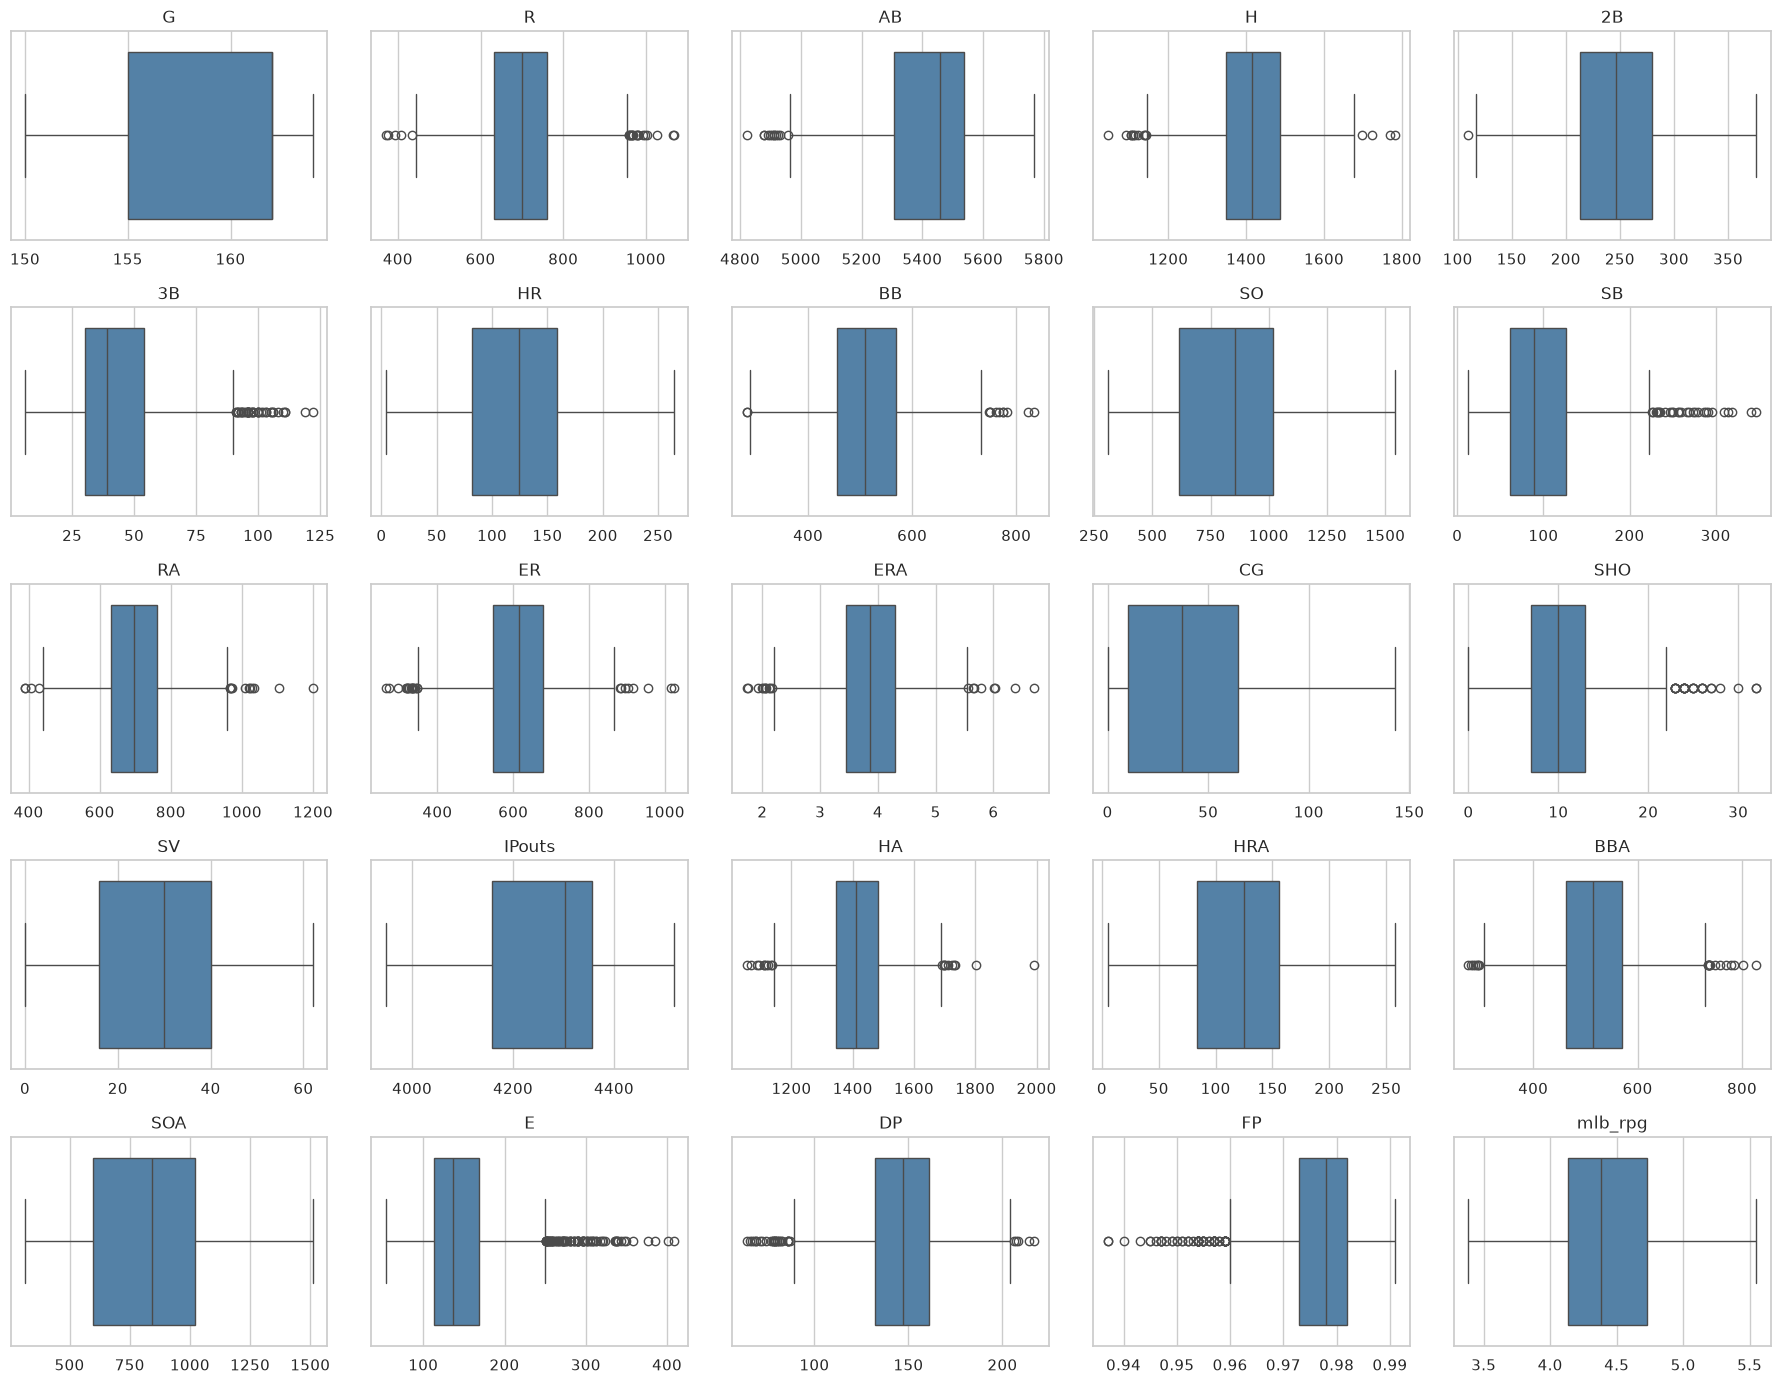

In [15]:
fig, axes = plt.subplots(5, 5, figsize=(18, 14))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=train[col], ax=ax, color='steelblue')
    ax.set_title(col); ax.set_xlabel('')
plt.tight_layout()

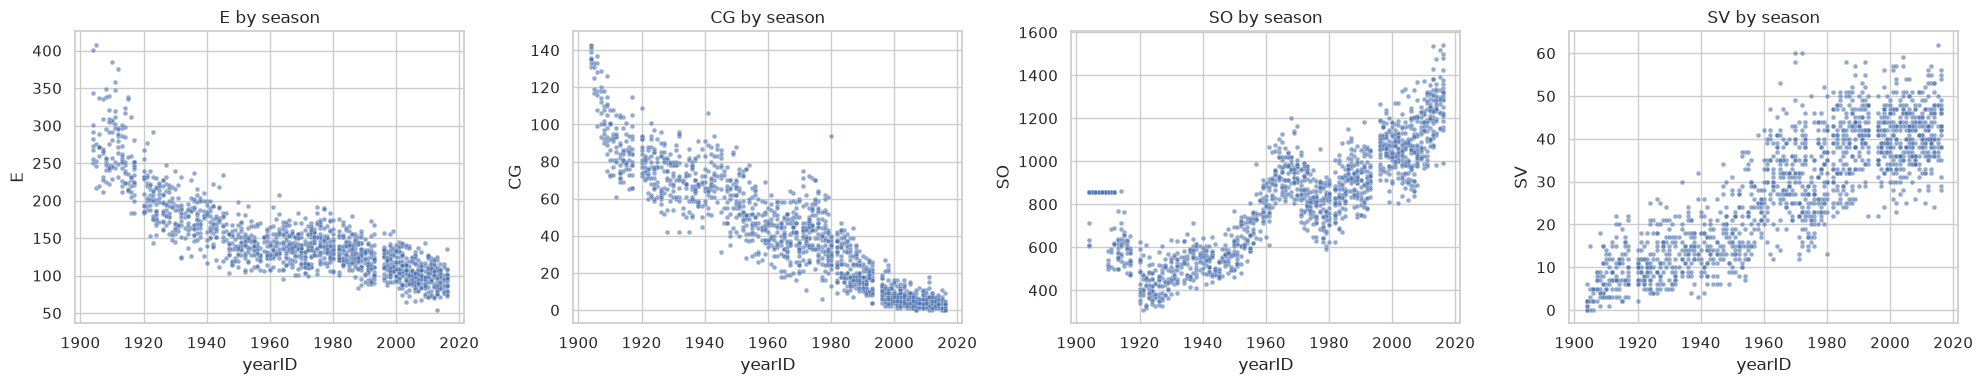

In [16]:
# Are outliers era effects? Errors, triples and complete games were much higher in the dead-ball era
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['E', 'CG', 'SO', 'SV']):
    sns.scatterplot(data=train, x='yearID', y=col, s=12, ax=ax, alpha=0.6)
    ax.set_title(f'{col} by season')
plt.tight_layout()

Most "outliers" are **era effects**, not errors: high errors (`E`) and complete games (`CG`) in early baseball, high strikeouts in modern baseball. Saves only became official in 1969; earlier seasons have retroactively credited saves, so they're lower but not zero. They're real seasons that passed every consistency check, so **we keep them**. If they turn out to matter, era-relative features (e.g. a stat divided by the league average for that year) can handle them during feature engineering.

### Target distribution

count    1412.000000
mean       79.230878
std        13.295069
min        36.000000
25%        71.000000
50%        80.000000
75%        89.000000
max       116.000000
Name: W, dtype: float64


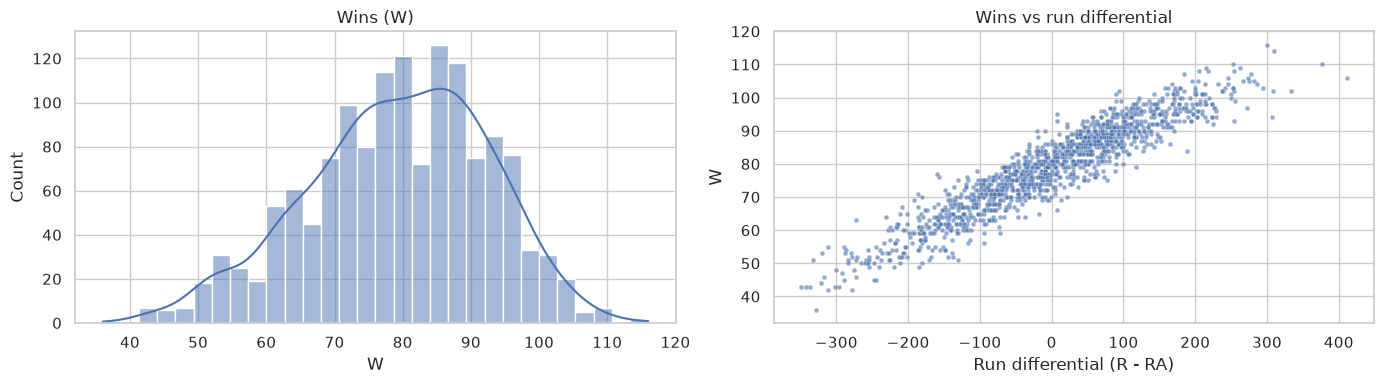

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train['W'], bins=30, kde=True, ax=axes[0]); axes[0].set_title('Wins (W)')
sns.scatterplot(data=train, x=train.R - train.RA, y='W', s=12, alpha=0.6, ax=axes[1])
axes[1].set_xlabel('Run differential (R - RA)'); axes[1].set_title('Wins vs run differential')
plt.tight_layout()
print(train['W'].describe())

## 9. Save cleaned data

### Column roles
Defined here so later notebooks use the same split.

In [18]:
TARGET = 'W'
ID_COL = 'ID'
ANALYSIS_ONLY = ['yearID']                       # in train only, never a feature
LABEL_ONLY = ['decade_label']                    # duplicates the decade dummies; for grouping/plots
CATEGORICAL = ['teamID']
FEATURES = [c for c in pred.columns if c not in [ID_COL, *LABEL_ONLY]]

extra = set(train.columns) - set(pred.columns)
assert extra == {TARGET, *ANALYSIS_ONLY}, f'Unexpected train-only columns {extra}: restart the kernel and Run All'
assert set(FEATURES) <= set(train.columns)
print(f'{len(FEATURES)} candidate features ({len(CATEGORICAL)} categorical):', FEATURES)

46 candidate features (1 categorical): ['teamID', 'G', 'R', 'AB', 'H', '2B', '3B', 'HR', 'BB', 'SO', 'SB', 'RA', 'ER', 'ERA', 'CG', 'SHO', 'SV', 'IPouts', 'HA', 'HRA', 'BBA', 'SOA', 'E', 'DP', 'FP', 'mlb_rpg', 'era_1', 'era_2', 'era_3', 'era_4', 'era_5', 'era_6', 'era_7', 'era_8', 'decade_1900', 'decade_1910', 'decade_1920', 'decade_1930', 'decade_1940', 'decade_1950', 'decade_1960', 'decade_1970', 'decade_1980', 'decade_1990', 'decade_2000', 'decade_2010']


In [19]:
pred = pred[[c for c in train.columns if c in pred.columns]]   # same column order as train

train.to_csv(OUT_DIR / 'train_clean.csv', index=False)
pred.to_csv(OUT_DIR / 'predict_clean.csv', index=False)
print('Saved:', OUT_DIR / 'train_clean.csv', train.shape, '|', OUT_DIR / 'predict_clean.csv', pred.shape)

Saved: ../Data/train_clean.csv (1412, 50) | ../Data/predict_clean.csv (400, 48)


## Summary
| Issue | Action |
|---|---|
| No missing values / duplicates | none needed |
| `yearID` absent from predict | by design: kept in train for analysis/CV only, not a feature |
| `win_bins` leaks target | dropped |
| `year_label` duplicates `yearID` | dropped |
| `SO`, `DP` stored as float | cast to int |
| Boolean dummies | cast to 0/1 |
| `decade_1910` includes 1904–1909 | added `decade_1900` from `decade_label`; `decade_1910` now 1910–1919 only |
| `decade_label` duplicates the dummies | kept for grouping/plots, not a feature |
| Extreme values (E, CG, SO, SV) | real era effects, kept |

**Next:** `02_feature_engineering.ipynb` adds run-based, close-game, era-relative and rate features.